#1. What is K-Nearest Neighbors (KNN)?
KNN is a supervised Machine Learning algorithm used for both:
- Classification – predicting categories.
- Regression – predicting numerical values.

#How KNN works
- Choose the value of K.
- Calculate the distance between the new data point and existing points.
- Find the K nearest neighbors.
- For regression, calculate their average target value.
- Return the prediction.

#Important concepts:
- K = Number of nearest neighbors.
- Distance = How close two data points are.
- Euclidean Distance = Commonly used distance measurement.
- Feature Scaling = Important because KNN depends on distances.

#2. Today's practical plan
1. Understand KNN.
2. Learn Euclidean Distance.
3. Implement KNN Regressor.
4. Understand the effect of K values.
5. Evaluate using MAE, RMSE and R².
6. Compare KNN with previous algorithms.


#3. Practical — Dataset Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes

# Load dataset
diabetes = load_diabetes()

# Create DataFrame
df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

# Add target column
df["Disease_Progression"] = diabetes.target

print("Dataset Loaded Successfully!")
print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset Loaded Successfully!

First 5 Rows:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  Disease_Progression  
0 -0.002592  0.019907 -0.017646                151.0  
1 -0.039493 -0.068332 -0.092204                 75.0  
2 -0.002592  0.002861 -0.025930                141.0  
3  0.034309  0.022688 -0.009362                206.0  
4 -0.002592 -0.031988 -0.046641                135.0  

Dataset Shape: (442, 11)


#Step 2: Separate Features and Target

In [2]:
# Separate input features and target

X = df.drop("Disease_Progression", axis=1)
y = df["Disease_Progression"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (442, 10)
Target Shape: (442,)


#Step 3: Train-Test Split

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (353, 10)
Testing Features: (89, 10)
Training Target: (353,)
Testing Target: (89,)


#Step 4: Feature Scaling

In [4]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Original Training Shape:", X_train.shape)
print("Scaled Training Shape:", X_train_scaled.shape)

print("\nFirst 5 Scaled Rows:")
print(X_train_scaled[:5])

Original Training Shape: (353, 10)
Scaled Training Shape: (353, 10)

First 5 Scaled Rows:
[[ 1.49836523  1.06136988  0.21990201  1.13887373  0.72847289  1.05589332
  -0.82445065  0.71103773  0.54748197 -0.06144896]
 [-0.22885822  1.06136988 -0.41936607 -0.71059105 -0.4249289   0.27242452
  -1.52979055  1.4842858  -0.01975653  0.36723647]
 [ 0.08518241 -0.94217861  1.01898711  1.99247286 -0.30958872 -0.32669867
  -0.11911075 -0.06221033  0.3312366  -0.31866022]
 [-0.621409   -0.94217861 -0.78466212 -0.63945779 -1.17464007 -1.21550781
   0.66460025 -0.83545839 -1.06968217 -2.71929861]
 [-0.54289885 -0.94217861 -1.4239302  -1.7064567  -0.79978448 -1.11016747
   1.29156905 -1.60870645 -0.80285867 -0.91881982]]


#Step 5: Train KNN Regression Model

In [5]:
from sklearn.neighbors import KNeighborsRegressor

# Create KNN model with K = 5
knn_model = KNeighborsRegressor(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN Model Trained Successfully!")
print("Number of Neighbors (K):", knn_model.n_neighbors)

KNN Model Trained Successfully!
Number of Neighbors (K): 5


#Step 6: Make Predictions

In [6]:
# Predict using KNN model
y_pred = knn_model.predict(X_test_scaled)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("First 10 Predictions:")
print(results.head(10))

First 10 Predictions:
   Actual  Predicted
0   219.0      125.6
1    70.0      160.2
2   202.0      153.0
3   230.0      238.0
4   111.0      153.4
5    84.0      150.4
6   242.0      246.2
7   272.0      170.0
8    94.0       94.4
9    96.0      104.6


#Step 7: Model Evaluation

In [7]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("KNN Model Evaluation")
print("--------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

KNN Model Evaluation
--------------------
MAE: 42.777528089887646
MSE: 3047.449887640449
RMSE: 55.203712625515045
R2 Score: 0.42480887066066253


#Step 8: Understanding KNN Performance

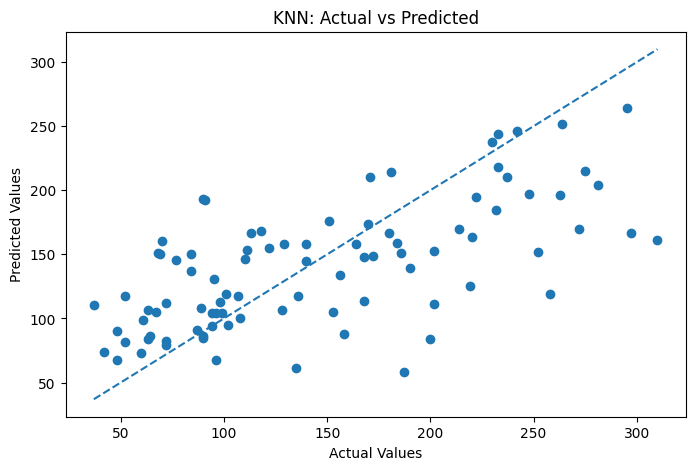

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("KNN: Actual vs Predicted")

plt.show()

#Step 10: Effect of K in KNN

In [9]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

k_values = [1, 3, 5, 7, 9, 11, 15]

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=k))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    print(f"K = {k}, Cross-validation MAE = {-scores.mean():.2f}")

K = 1, Cross-validation MAE = 60.79
K = 3, Cross-validation MAE = 51.33
K = 5, Cross-validation MAE = 50.36
K = 7, Cross-validation MAE = 48.37
K = 9, Cross-validation MAE = 48.07
K = 11, Cross-validation MAE = 48.08
K = 15, Cross-validation MAE = 48.09


#Step 11: Understand the Results

K = 1, Cross-validation MAE = 60.79


K = 3, Cross-validation MAE = 51.33

K = 5, Cross-validation MAE = 50.36

K = 7, Cross-validation MAE = 48.37

K = 9, Cross-validation MAE = 48.07

K = 11, Cross-validation MAE = 48.08

K = 15, Cross-validation MAE = 48.09

#Step 12: Train the Final KNN Model

In [10]:
final_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=9))
])

# Train on complete training data
final_knn.fit(X_train, y_train)

# Predict on test data
final_predictions = final_knn.predict(X_test)

# Evaluate
final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("Final KNN Model (K = 9)")
print("----------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

Final KNN Model (K = 9)
----------------------
MAE: 44.18601747815231
RMSE: 55.41631614819106
R2 Score: 0.4203699249844848
